# Build Your Own Word2Vec: Moby Dick
Training Word2Vec on Herman Melville's *Moby-Dick* (Project Gutenberg #2701).

This notebook contains 2 runs on the same text:  1) Skip-Gram and 2) CBOW

In [1]:
# ===== DOWNLOAD MOBY DICK FROM PROJECT GUTENBERG =====
# Saves the book as my_text.txt, which the template reads when DATASET = "my_file".
!wget -q -O my_text.txt https://www.gutenberg.org/cache/epub/2701/pg2701.txt
!wc -w my_text.txt    # word count, to confirm the download worked


215845 my_text.txt


In [2]:
# =====================================================================================
#  BUILD YOUR OWN WORD2VEC: A STEP-BY-STEP TEMPLATE (works with any text)
# =====================================================================================
#  HOW TO USE THIS CELL
#   1. Paste this whole cell into Google Colab.
#   2. In STEP 1, pick a dataset (or use your own file).
#   3. Work down the steps. Every line marked  # TODO  is yours to fill in.
#      Anything left as None gets skipped with a "TODO" message instead of crashing.
#   4. Re-run the cell after each step you finish. Read every printed output.
#
#  THE BIG IDEA: "You shall know a word by the company it keeps."
#  Word2Vec reads lots of text and gives every word an "address" (a list of numbers).
#  Words that appear in similar company end up with similar addresses.
# =====================================================================================

# ---------- STEP 0: INSTALL AND IMPORT (already done for you) ------------------------
%pip -q install -U "gensim>=4.3" "scikit-learn>=1.3" "matplotlib>=3.7" "seaborn>=0.13" nltk

import re
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import gensim.downloader as api
from gensim.models import Word2Vec
from gensim.models.word2vec import Text8Corpus
from gensim.utils import simple_preprocess          # lowercases, strips punctuation, splits into words
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
np.random.seed(SEED)


In [3]:
# ---------- STEP 1: CHOOSE YOUR DATASET ----------------------------------------------
#  Pick ONE name and put it in DATASET below.
#
#   "brown"        ~1.0M words  | 500 texts of 1960s American English: news, fiction, science, humor
#   "gutenberg"    ~2.1M words  | 18 classic books (Austen, Shakespeare, the Bible, Moby Dick...)
#   "reuters"      ~1.3M words  | 10,000+ business and financial news stories
#   "movie_reviews"~1.3M words  | 2,000 movie reviews (positive and negative)
#   "newsgroups"                | 18,000 online forum posts on 20 topics (space, cars, religion, hockey...)
#   "text8"        2M words     | Wikipedia, the dataset from class (capped at MAX_TOKENS)
#   "my_file"                   | YOUR OWN .txt file: upload it in Colab's Files panel (left sidebar)
#   You can also go to: https://www.gutenberg.org and download a book and use that
#.  i.e.: for pride and prejudice: !wget -q -O my_text.txt https://www.gutenberg.org/cache/epub/1342/pg1342.txt
#  Tip: a word needs to appear at least MIN_COUNT times to get an address.
#  Choose words to explore that actually show up in YOUR dataset (a hockey word won't be in Austen).

# TODO: change this to the dataset you picked
DATASET = "my_file"    # Moby Dick, downloaded to my_text.txt in the cell above
MY_FILE = "my_text.txt"           # only used if DATASET = "my_file"
MAX_TOKENS = 2_000_000            # cap for big datasets (text8 and my_file)


In [4]:
# ---------- STEP 2: LOAD THE TEXT AS A LIST OF SENTENCES (done for you) --------------
#  Word2Vec needs a LIST OF LISTS: each inner list is one sentence, already split into
#  lowercase words. Example: [["the", "cat", "sat"], ["a", "dog", "ran"]]

def clean(words):
    """Lowercase and keep only real words (letters only)."""
    return [w.lower() for w in words if re.fullmatch(r"[A-Za-z]+", w)]

def load_sentences(name):
    if name in ("brown", "gutenberg", "reuters", "movie_reviews"):
        nltk.download(name, quiet=True)
        nltk.download("punkt", quiet=True)
        nltk.download("punkt_tab", quiet=True)
        corpus = getattr(nltk.corpus, name)          # e.g. nltk.corpus.brown
        return [s for s in (clean(sent) for sent in corpus.sents()) if len(s) > 1]
    if name == "newsgroups":
        from sklearn.datasets import fetch_20newsgroups
        posts = fetch_20newsgroups(subset="all", remove=("headers", "footers", "quotes")).data
        return [s for s in (simple_preprocess(p) for p in posts) if len(s) > 1]
    if name == "text8":
        path = api.load("text8", return_path=True)   # the class fix: skip Gensim's broken loader
        sentences, kept = [], 0
        for chunk in Text8Corpus(path):
            sentences.append(chunk)
            kept += len(chunk)
            if kept >= MAX_TOKENS:
                break
        return sentences
    if name == "my_file":
        with open(MY_FILE, encoding="utf-8", errors="ignore") as f:
            lines = [simple_preprocess(line) for line in f]
        sentences, kept = [], 0
        for s in lines:
            if len(s) > 1:
                sentences.append(s)
                kept += len(s)
            if kept >= MAX_TOKENS:
                break
        return sentences
    raise ValueError(f"Unknown DATASET: {name}")

sentences = load_sentences(DATASET)

# TODO: print how many sentences you loaded, the total number of words,
#       and the first sentence, so you can SEE what Word2Vec will read.
#       Hint: len(sentences), sum(len(s) for s in sentences), sentences[0]
print(f"Sentences loaded: {len(sentences):,}")
print(f"Total words:      {sum(len(s) for s in sentences):,}")
print("First sentence:  ", sentences[0])


Sentences loaded: 18,922
Total words:      212,079
First sentence:   ['the', 'project', 'gutenberg', 'ebook', 'of', 'moby', 'dick', 'or', 'the', 'whale']


## Run 1: Skip-gram (SG = 1)

**Skip-gram** looks at one word and guesses the words around it.

Example: given **"whale"**, guess "white," "sea," "harpoon."


In [7]:
# ---------- STEP 3: CHOOSE YOUR SETTINGS ---------------------------------------------
#  These are the knobs. Write a comment next to each saying WHY you chose that value.

# TODO: how many numbers per word? (class used 100)
VECTOR_SIZE = 50      # Moby Dick is relatively small (215,845 words), so 50 numbers is enough without picking up noise
# TODO: how many words of context on each side? (class used 5)
WINDOW      = 5       # each line is only ~10-12 words, so 5 each side covers most of it
# TODO: drop words seen fewer than this many times (class used 5)
MIN_COUNT   = 5       # rarer words get random neighbors, so drop anything seen under 5 times
# TODO: 1 = skip-gram, 0 = CBOW
SG          = 1       # Run 1: skip-gram, good for small texts and rare words.  I choose CBOW for a 2nd run below
NEGATIVE    = 10      # small texts learn better with more noise words
# TODO: how many passes through the text? (class used 5)
EPOCHS      = 30      # small text needs more passes


In [8]:
# ---------- STEP 4: TRAIN THE MODEL --------------------------------------------------
#  Build Word2Vec(...) using sentences= and every setting from STEP 3,
#  plus workers=1 and seed=SEED so your results are repeatable.

# TODO: model = Word2Vec(sentences=..., vector_size=..., ...)
model = Word2Vec(
    sentences=sentences,
    vector_size=VECTOR_SIZE,
    window=WINDOW,
    min_count=MIN_COUNT,
    sg=SG,
    negative=NEGATIVE,
    workers=1,
    seed=SEED,
    epochs=EPOCHS,
)

if model is not None:
    print(f"Vocabulary size: {len(model.wv):,} words")
    print("Most frequent words:", model.wv.index_to_key[:10])
else:
    print("STEP 4 TODO: train your model.")


Vocabulary size: 4,267 words
Most frequent words: ['the', 'of', 'and', 'to', 'in', 'that', 'it', 'his', 'he', 'but']


In [9]:
# ---------- STEP 5: SAVE YOUR GAME ---------------------------------------------------
MODEL_PATH = f"word2vec_{DATASET}.model"
if model is not None:
    # TODO: save the model to MODEL_PATH, then load it back into model
    # Hint: model.save(...) and Word2Vec.load(...)
    model.save(MODEL_PATH)
    model = Word2Vec.load(MODEL_PATH)
    print(f"Saved and reloaded: {MODEL_PATH}")


Saved and reloaded: word2vec_my_file.model


In [10]:
# ---------- STEP 6: WHO LIVES NEAR? (nearest neighbors) ------------------------------
#  Pick 3 words that matter in YOUR dataset (check they're in the vocabulary first).

# TODO: e.g. ["money", "god", "love"]  -> choose words from YOUR dataset
MY_WORDS = ["whale", "ahab", "sea"]    # three words of Moby Dick

def in_vocab(word):
    ok = model is not None and word in model.wv.key_to_index
    if model is not None and not ok:
        print(f"'{word}' is out of vocabulary (OOV). Try a more common word.")
    return ok

for word in MY_WORDS:
    if in_vocab(word):
        # TODO: print the 5 nearest neighbors of word
        # Hint: model.wv.most_similar(word, topn=5)
        print(f"\nTop 5 neighbors of '{word}':")
        for neighbor, score in model.wv.most_similar(word, topn=5):
            print(f"  {neighbor:>15s}  {score: .3f}")



Top 5 neighbors of 'whale':
            sperm   0.729
           whales   0.700
         beheaded   0.698
      heidelburgh   0.689
            folio   0.674

Top 5 neighbors of 'ahab':
         starbuck   0.663
           mayhew   0.661
        advancing   0.639
            fiend   0.628
          whisper   0.624

Top 5 neighbors of 'sea':
        blackness   0.681
          floated   0.657
           serene   0.647
             salt   0.643
            south   0.619


In [11]:
# ---------- STEP 7: MEASURE ONE PAIR (cosine similarity) -----------------------------
# TODO: two words you think are related, e.g. ("man", "woman")
PAIR = ("ahab", "captain")    # Ahab is the captain

if all(PAIR) and all(in_vocab(w) for w in PAIR):
    # TODO: print the cosine similarity between the two words
    # Hint: model.wv.similarity(PAIR[0], PAIR[1])
    score = model.wv.similarity(PAIR[0], PAIR[1])
    print(f"\nCosine similarity('{PAIR[0]}', '{PAIR[1]}') = {score:.3f}")



Cosine similarity('ahab', 'captain') = 0.453


In [12]:
# ---------- STEP 8: THE ANALOGY PROBE (B - A + C) ------------------------------------
# TODO: e.g. A="man", B="king", C="woman"  ->  king - man + woman
A, B, C = "ahab", "captain", "queequeg"    # captain - ahab + queequeg  ->  hoping for "harpooneer"

if all([A, B, C]) and all(in_vocab(w) for w in [A, B, C]):
    # TODO: print the top 5 results
    # Hint: model.wv.most_similar(positive=[B, C], negative=[A], topn=5)
    print(f"\nAnalogy probe: {B} - {A} + {C}")
    for word, score in model.wv.most_similar(positive=[B, C], negative=[A], topn=5):
        print(f"  {word:>15s}  {score: .3f}")



Analogy probe: captain - ahab + queequeg
           hussey   0.558
             mend   0.527
             said   0.506
            signs   0.503
            peleg   0.503


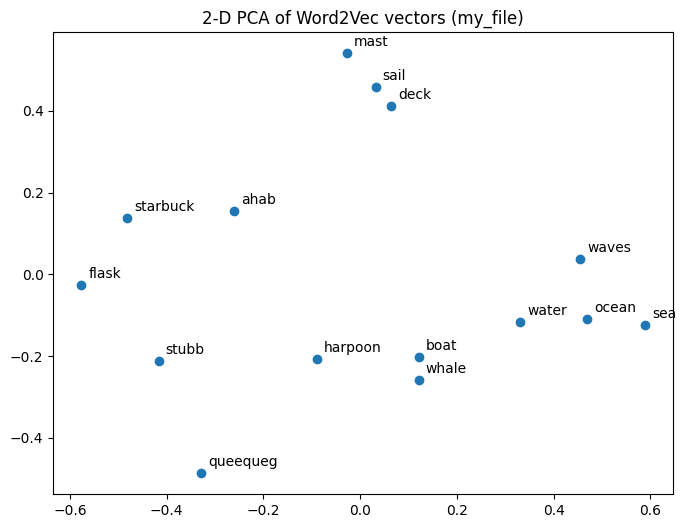

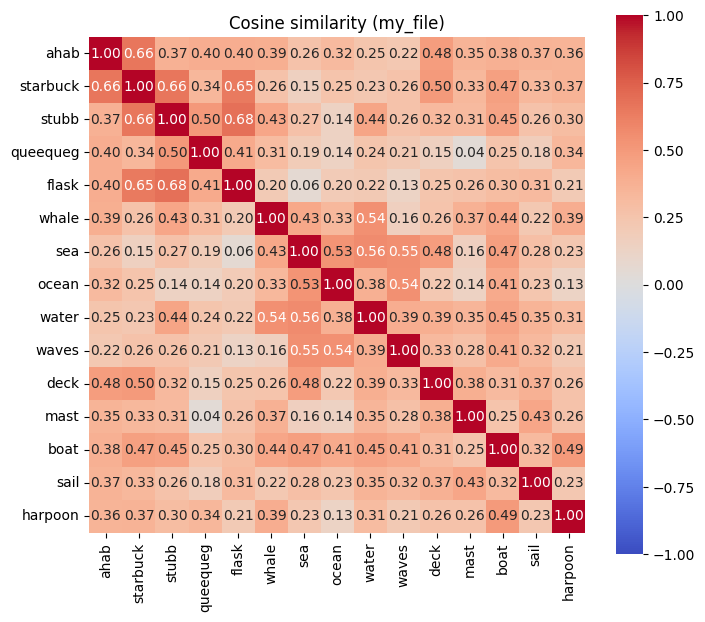

In [15]:
# ---------- STEP 9: DRAW THE MAP (PCA scatter + cosine heatmap) ----------------------
#  Choose 8-15 words in 2-3 "teams" you expect to cluster (e.g. 4 places, 4 people, 4 foods).

# TODO: your list of words
PLOT_WORDS = [
    "ahab", "starbuck", "stubb", "queequeg", "flask",    # team 1: the crew
    "whale", "sea", "ocean", "water", "waves",           # team 2: the sea
    "deck", "mast", "boat", "sail", "harpoon",           # team 3: the ship
]

plot_words = [w for w in PLOT_WORDS if in_vocab(w)]
if len(plot_words) >= 2:
    vectors = np.vstack([model.wv[w] for w in plot_words])
    vectors = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)   # length 1: only direction counts

    # TODO: run PCA with n_components=2 on vectors and get 2-D coordinates
    # Hint: PCA(n_components=2, random_state=SEED).fit_transform(vectors)
    coords = PCA(n_components=2, random_state=SEED).fit_transform(vectors)

    if coords is not None:
        plt.figure(figsize=(8, 6))
        plt.scatter(coords[:, 0], coords[:, 1])
        for w, (x, y) in zip(plot_words, coords):
            plt.annotate(w, (x, y), xytext=(5, 5), textcoords="offset points")
        plt.title(f"2-D PCA of Word2Vec vectors ({DATASET})")
        plt.show()
        print("\n" * 2)  #space between plots

    # TODO: compute the cosine similarity table for vectors, then draw it with sns.heatmap
    # Hint: cosine_similarity(vectors)
    sim = cosine_similarity(vectors)
    if sim is not None:
        plt.figure(figsize=(8, 7))
        sns.heatmap(sim, xticklabels=plot_words, yticklabels=plot_words,
                    annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm", square=True)
        plt.title(f"Cosine similarity ({DATASET})")
        plt.show()


In [16]:
# ---------- STEP 10: PLAY DETECTIVE --------------------------------------------------
#  For any word that surprised you, check how often it appeared and who its neighbors are.

# TODO: words whose results surprised you
SUSPECTS = ["ishmael", "moby", "white", "pequod"]    # narrator, the whale's name, its color, the ship
for w in SUSPECTS:
    if in_vocab(w):
        # TODO: print the word, its count, and its 3 nearest neighbors
        # Hint: model.wv.get_vecattr(w, "count")
        count = model.wv.get_vecattr(w, "count")
        top3 = [n for n, _ in model.wv.most_similar(w, topn=3)]
        print(f"{w:>10s}  appears {count:>5,} times   neighbors: {top3}")


   ishmael  appears    20 times   neighbors: ['passenger', 'forget', 'lest']
      moby  appears    89 times   neighbors: ['dick', 'survive', 'recalled']
     white  appears   280 times   neighbors: ['glistening', 'depths', 'cedar']
    pequod  appears   176 times   neighbors: ['ship', 'rachel', 'meets']


## Run 2: CBOW (SG = 0)

**CBOW** does the opposite: it looks at the words around and guesses the missing word.

Example: given "the white ___ swam," guess **"whale."**


In [17]:
# ---------- STEP 3: CHOOSE YOUR SETTINGS ---------------------------------------------
#  These are the knobs. Write a comment next to each saying WHY you chose that value.

# TODO: how many numbers per word? (class used 100)
VECTOR_SIZE = 50    # same as Skip Gram for camparison
# TODO: how many words of context on each side? (class used 5)
WINDOW      = 5    # same as Skip Gram for camparison
# TODO: drop words seen fewer than this many times (class used 5)
MIN_COUNT   = 5    # keeps the main characters, drops one-off words
# TODO: 1 = skip-gram, 0 = CBOW
SG          = 0    # Run 2: CBOW
NEGATIVE    = 10      # noise words per real pair (Gensim's default) - same as Skip Gram for camparison
# TODO: how many passes through the text? (class used 5)
EPOCHS      = 30    # same as Skip Gram for camparison


In [18]:
# ---------- STEP 4: TRAIN THE MODEL --------------------------------------------------
#  Build Word2Vec(...) using sentences= and every setting from STEP 3,
#  plus workers=1 and seed=SEED so your results are repeatable.

# TODO: model = Word2Vec(sentences=..., vector_size=..., ...)
model = Word2Vec(
    sentences=sentences,
    vector_size=VECTOR_SIZE,
    window=WINDOW,
    min_count=MIN_COUNT,
    sg=SG,
    negative=NEGATIVE,
    workers=1,
    seed=SEED,
    epochs=EPOCHS,
)

if model is not None:
    print(f"Vocabulary size: {len(model.wv):,} words")
    print("Most frequent words:", model.wv.index_to_key[:10])
else:
    print("STEP 4 TODO: train your model.")


Vocabulary size: 4,267 words
Most frequent words: ['the', 'of', 'and', 'to', 'in', 'that', 'it', 'his', 'he', 'but']


In [19]:
# ---------- STEP 5: SAVE YOUR GAME ---------------------------------------------------
MODEL_PATH = f"word2vec_{DATASET}.model"
if model is not None:
    # TODO: save the model to MODEL_PATH, then load it back into model
    # Hint: model.save(...) and Word2Vec.load(...)
    model.save(MODEL_PATH)
    model = Word2Vec.load(MODEL_PATH)
    print(f"Saved and reloaded: {MODEL_PATH}")


Saved and reloaded: word2vec_my_file.model


In [20]:
# ---------- STEP 6: WHO LIVES NEAR? (nearest neighbors) ------------------------------
#  Pick 3 words that matter in YOUR dataset (check they're in the vocabulary first).

# TODO: e.g. ["money", "god", "love"]  -> choose words from YOUR dataset
MY_WORDS = ["whale", "ahab", "sea"]    # three words at the heart of Moby Dick

def in_vocab(word):
    ok = model is not None and word in model.wv.key_to_index
    if model is not None and not ok:
        print(f"'{word}' is out of vocabulary (OOV). Try a more common word.")
    return ok

for word in MY_WORDS:
    if in_vocab(word):
        # TODO: print the 5 nearest neighbors of word
        # Hint: model.wv.most_similar(word, topn=5)
        print(f"\nTop 5 neighbors of '{word}':")
        for neighbor, score in model.wv.most_similar(word, topn=5):
            print(f"  {neighbor:>15s}  {score: .3f}")



Top 5 neighbors of 'whale':
           whales   0.689
             hump   0.593
            bears   0.530
         whalemen   0.500
              tun   0.492

Top 5 neighbors of 'ahab':
            voice   0.722
            peleg   0.700
            sleet   0.630
           bildad   0.630
           mayhew   0.626

Top 5 neighbors of 'sea':
           waters   0.558
             east   0.526
             seas   0.517
             mild   0.506
          rolling   0.490


In [21]:
# ---------- STEP 7: MEASURE ONE PAIR (cosine similarity) -----------------------------
# TODO: two words you think are related, e.g. ("man", "woman")
PAIR = ("ahab", "captain")    # Ahab is the captain

if all(PAIR) and all(in_vocab(w) for w in PAIR):
    # TODO: print the cosine similarity between the two words
    # Hint: model.wv.similarity(PAIR[0], PAIR[1])
    score = model.wv.similarity(PAIR[0], PAIR[1])
    print(f"\nCosine similarity('{PAIR[0]}', '{PAIR[1]}') = {score:.3f}")



Cosine similarity('ahab', 'captain') = 0.240


In [22]:
# ---------- STEP 8: THE ANALOGY PROBE (B - A + C) ------------------------------------
# TODO: e.g. A="man", B="king", C="woman"  ->  king - man + woman
A, B, C = "ahab", "captain", "queequeg"    # captain - ahab + queequeg  ->  hoping for "harpooneer"

if all([A, B, C]) and all(in_vocab(w) for w in [A, B, C]):
    # TODO: print the top 5 results
    # Hint: model.wv.most_similar(positive=[B, C], negative=[A], topn=5)
    print(f"\nAnalogy probe: {B} - {A} + {C}")
    for word, score in model.wv.most_similar(positive=[B, C], negative=[A], topn=5):
        print(f"  {word:>15s}  {score: .3f}")



Analogy probe: captain - ahab + queequeg
           thinks   0.498
            signs   0.482
             said   0.468
      proceedings   0.446
             mend   0.439


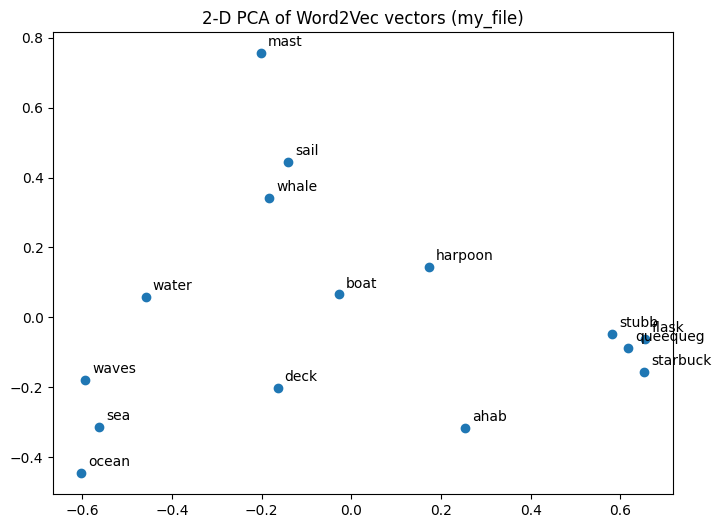

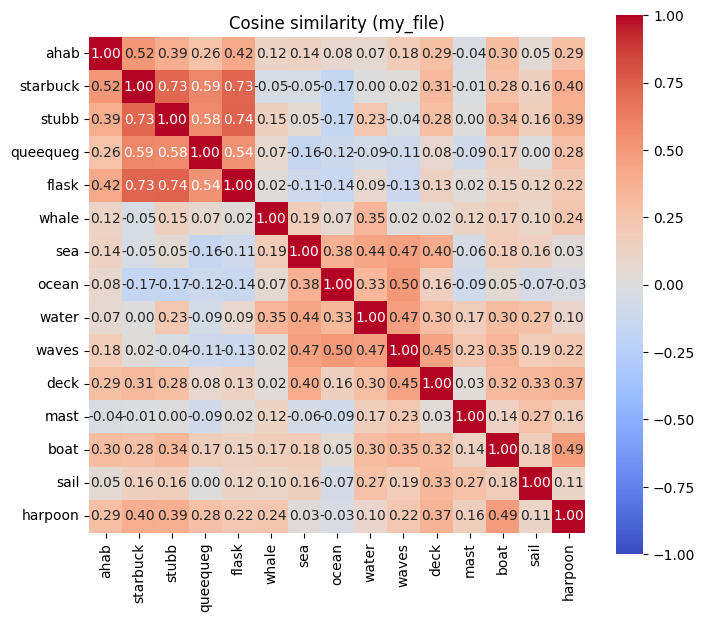

In [24]:
# ---------- STEP 9: DRAW THE MAP (PCA scatter + cosine heatmap) ----------------------
#  Choose 8-15 words in 2-3 "teams" you expect to cluster (e.g. 4 places, 4 people, 4 foods).

# TODO: your list of words
PLOT_WORDS = [
    "ahab", "starbuck", "stubb", "queequeg", "flask",    # team 1: the crew
    "whale", "sea", "ocean", "water", "waves",           # team 2: the sea
    "deck", "mast", "boat", "sail", "harpoon",           # team 3: the ship
]

plot_words = [w for w in PLOT_WORDS if in_vocab(w)]
if len(plot_words) >= 2:
    vectors = np.vstack([model.wv[w] for w in plot_words])
    vectors = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)   # length 1: only direction counts

    # TODO: run PCA with n_components=2 on vectors and get 2-D coordinates
    # Hint: PCA(n_components=2, random_state=SEED).fit_transform(vectors)
    coords = PCA(n_components=2, random_state=SEED).fit_transform(vectors)

    if coords is not None:
        plt.figure(figsize=(8, 6))
        plt.scatter(coords[:, 0], coords[:, 1])
        for w, (x, y) in zip(plot_words, coords):
            plt.annotate(w, (x, y), xytext=(5, 5), textcoords="offset points")
        plt.title(f"2-D PCA of Word2Vec vectors ({DATASET})")
        plt.show()
        print("\n" *2)

    # TODO: compute the cosine similarity table for vectors, then draw it with sns.heatmap
    # Hint: cosine_similarity(vectors)
    sim = cosine_similarity(vectors)
    if sim is not None:
        plt.figure(figsize=(8, 7))
        sns.heatmap(sim, xticklabels=plot_words, yticklabels=plot_words,
                    annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm", square=True)
        plt.title(f"Cosine similarity ({DATASET})")
        plt.show()


In [25]:
# ---------- STEP 10: PLAY DETECTIVE --------------------------------------------------
#  For any word that surprised you, check how often it appeared and who its neighbors are.

# TODO: words whose results surprised you
SUSPECTS = ["ishmael", "moby", "white", "pequod"]    # narrator, the whale's name, its color, the ship
for w in SUSPECTS:
    if in_vocab(w):
        # TODO: print the word, its count, and its 3 nearest neighbors
        # Hint: model.wv.get_vecattr(w, "count")
        count = model.wv.get_vecattr(w, "count")
        top3 = [n for n, _ in model.wv.most_similar(w, topn=3)]
        print(f"{w:>10s}  appears {count:>5,} times   neighbors: {top3}")


   ishmael  appears    20 times   neighbors: ['forget', 'seams', 'fool']
      moby  appears    89 times   neighbors: ['dick', 'chase', 'activity']
     white  appears   280 times   neighbors: ['headed', 'stricken', 'dead']
    pequod  appears   176 times   neighbors: ['forecastle', 'nantucket', 'ship']


## STEP 11: Reflect

**Question 1.** Which neighbor or score surprised you most, and what in the TEXT explains it?

*Your answer:*

**Skip-gram:** The most surprising result was in Skip-gram, where "whale" was linked to "heidelburgh" and "folio." Skip-gram connected words that appeared in the same scenes: the book compares a whale's head to a giant wine cask in Heidelberg and sorts whales into "folio" sizes like books.

**CBOW:** CBOW connected words used in similar situations. For example, "whale" was linked to "whales" and "whalemen," while "Ahab" was linked to other captains like Peleg, Bildad, and Mayhew.

Skip-gram learned which words appeared together, while CBOW learned which words were used in similar contexts.


**Question 2.** Did your "teams" cluster on the heatmap? Did the PCA plot tell the same story?

*Your answer:*

**Skip-gram:** The teams partly clustered. The crew was the strongest team, since Starbuck, Stubb, and Flask are often named together (0.65 to 0.68), and Ahab joined them (0.66 with Starbuck). Queequeg sat apart. The sea words also grouped well (0.53 to 0.56). The ship words scored low on the heatmap, but on the PCA plot mast, sail, and deck appeared close together, so the two plots didn't fully agree. Boat and harpoon moved near whale instead, forming an unexpected "hunt" group from the chase scenes.

**CBOW:** The crew was even tighter (0.73 to 0.74), and Queequeg joined them (0.54 to 0.59), but Ahab moved away. The sea words still grouped, but more weakly (0.33 to 0.50), and the ship words fell apart, with mast near 0 with everything. The PCA plot matched, with the crew in a tight group on one side, the sea words on the other, and Ahab on his own.

CBOW separated the teams more sharply, while Skip-gram kept more connections between teams, like whale with water (0.54 vs 0.35) and Ahab with deck (0.48 vs 0.29).


**Question 3.** Which words were rare, and how did that affect their neighbors?

*Your answer:*

**Skip-gram:** "Ishmael" was the rarest word I checked, appearing only 20 times even though he narrates the whole book, because he mostly says "I." His neighbors were random: "passenger," "forget," "lest." More frequent words made more sense: "Pequod" (176 times) was linked to "ship," "rachel," and "meets," because the Pequod meets the ship *Rachel*, and "moby" (89 times) was linked to "dick."

**CBOW:** "Ishmael" was still random: "forget," "seams," "fool." The frequent words still made sense: "Pequod" was linked to "forecastle," "nantucket," and "ship," and "moby" was still linked to "dick." "White" (280 times) was linked to "headed" and "dead," which likely come from phrases like "white-headed" and "dead whale."

Rare words had unreliable neighbors in both runs. Skip-gram is supposed to handle rare words better, but with only 20 examples, neither run could learn much about Ishmael.


**Question 4.** Change ONE setting (SG, EPOCHS, WINDOW, or the dataset), retrain, and describe what changed.

*Your answer:*

I changed **SG from 1 (Skip-gram) to 0 (CBOW)** and kept every other setting the same (vector size 50, window 5, min count 5, negative 10, 30 epochs). The vocabulary stayed at 4,267 words, but the results changed:
- **Neighbors:** Skip-gram found words from the same scenes, while CBOW found words that can be swapped in. "Whale" went from "sperm," "beheaded," and "heidelburgh" to "whales," "hump," and "whalemen." "Sea" went from "blackness," "floated," and "serene" to "waters" and "seas." "Ahab" went from "Starbuck" to other captains: "Peleg," "Bildad," and "Mayhew."
- **Scores:** Ahab–captain dropped from 0.453 to 0.240.
- **Analogy:** captain − ahab + queequeg got worse. Skip-gram found "Peleg," the captain who hires Queequeg, but CBOW only found general words like "thinks" and "proceedings."
- **Teams:** CBOW made the crew tighter (0.73 to 0.74) and separated the teams more sharply, but Ahab moved away from the crew and the ship words fell apart.

Overall, Skip-gram worked better for story connections, while CBOW worked better for finding similar words.
